#### Simulation settings

`Paths`

In [333]:
from pathlib import Path

ACC_CPP_DIR = Path("/home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/simulation/acc_cpp")
BINARY_FILE = ACC_CPP_DIR / "build/runner/acc_sim"
OUTPUT_ROOT = ACC_CPP_DIR / "results"


`Select Scenario NCAP`

In [334]:
SCENARIO_FILE = (
    ACC_CPP_DIR
    / "../../Data/OSC-NCAP-scenarios/OpenSCENARIO/NCAP"
    / "AEB_C2C_2023/NCAP_AEB_C2C_CCR_2023.xosc")


`NCAP Scenario settings`

In [335]:
EGO_NAME = "Ego"

# Simulation params
EGO_SPEED_KPH = 50.0
TARGET_SPEED_KPH = 20.0
TARGET_BRAKING_ENABLED = False

# Batch params
MARKOV_SEEDS = [10, 11, 12]
MARKOV_MISS_PROBABILITY = 0.1
MARKOV_MEAN_MISSING_SECONDS = 0.5


`Launcher settings`

In [336]:
TIMESTEP_SECONDS = 0.01
MAX_DURATION_SECONDS = 30  
TIME_GAP_SECONDS = 1.5  # Native ACC default following time gap.
SET_SPEED_MPS = None  # None uses the scenario's initial ego speed.
STOP_ON_COLLISION = True
DETAILED_LOGS = True
VIEWER = True 
NATIVE_REFERENCE = False  # False: target copies; True: live native targets.

# Esmini ObjectSensor: one measurement per simulation timestep.
IDEAL_SENSOR_ENABLED = True  # False keeps all-target copies for validation.
SENSOR_X_METRES = 0.0
SENSOR_Y_METRES = 0.0
SENSOR_Z_METRES = 0.5
SENSOR_HEADING_RADIANS = 0.0
SENSOR_NEAR_RANGE_METRES = 0.0
SENSOR_FAR_RANGE_METRES = 100.0
SENSOR_HORIZONTAL_FOV_RADIANS = 1.0471975511965976  # 60 degrees.



#### Prepare the batch

Shared scenario, ACC and sensor settings stay the same for every run. Markov requires the ideal sensor and target-copy mode.


In [337]:
import subprocess
import tempfile

binary = BINARY_FILE.resolve()
scenario = SCENARIO_FILE.resolve()

# Check bin file and xosc file exist
if not binary.is_file() or not scenario.is_file():
    raise FileNotFoundError("Check ACC_CPP_DIR, BINARY_FILE and SCENARIO_FILE.")

# Markov requirements
if MARKOV_SEEDS and (not IDEAL_SENSOR_ENABLED or NATIVE_REFERENCE):
    raise ValueError("Markov requires IDEAL_SENSOR_ENABLED=True and NATIVE_REFERENCE=False.")

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
batch_dir = Path(tempfile.mkdtemp(prefix="acc_batch_", dir=OUTPUT_ROOT.resolve()))
print("Batch output:", batch_dir)


Batch output: /home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/simulation/acc_cpp/results/acc_batch_bb7jgxnm


Shared command and batch execution


In [338]:
# Simulation args
command = [
    str(binary), "--scenario", str(scenario),
    "--controller", "acc",
    "--dt", str(TIMESTEP_SECONDS), "--duration", str(MAX_DURATION_SECONDS),
    "--time-gap", str(TIME_GAP_SECONDS),
    "--stop-on-collision", str(STOP_ON_COLLISION).lower(),
    "--detailed-logs", str(DETAILED_LOGS).lower(),
    "--viewer", str(VIEWER).lower(),
    "--native-reference", str(NATIVE_REFERENCE).lower(),
]

# Ideal sensor args
command += [
    "--ideal-sensor", str(IDEAL_SENSOR_ENABLED).lower(),
    "--sensor-x-m", str(SENSOR_X_METRES),
    "--sensor-y-m", str(SENSOR_Y_METRES),
    "--sensor-z-m", str(SENSOR_Z_METRES),
    "--sensor-heading-rad", str(SENSOR_HEADING_RADIANS),
    "--sensor-near-m", str(SENSOR_NEAR_RANGE_METRES),
    "--sensor-far-m", str(SENSOR_FAR_RANGE_METRES),
    "--sensor-horizontal-fov-rad", str(SENSOR_HORIZONTAL_FOV_RADIANS),
]

# NCAP scenario parameter overrides (not ACC cruise-speed settings).
command += [
    "--ego-name", EGO_NAME,
    "--ego-speed-kph", str(EGO_SPEED_KPH),
    "--target-speed-kph", str(TARGET_SPEED_KPH),
    "--target-braking", str(TARGET_BRAKING_ENABLED).lower(),
]

if SET_SPEED_MPS is not None:
    command += ["--set-speed", str(SET_SPEED_MPS)]
    

# Each entry gets a separate folder, even if a seed is repeated.
run_settings = [("ideal", 0)] + [("markov", seed) for seed in MARKOV_SEEDS]
runs = []


for index, (perception, seed) in enumerate(run_settings):
    label = "ideal" if perception == "ideal" else f"markov_seed_{seed}"
    output_dir = batch_dir / f"{index:02d}_{label}"
    
    run_command = command + [
        "--output-dir", str(output_dir),
        "--perception", perception,
        "--dropout-p", str(MARKOV_MISS_PROBABILITY if perception == "markov" else 0.0),
        "--mean-missing-s", str(MARKOV_MEAN_MISSING_SECONDS),
        "--seed", str(seed),
    ]
    
    print("-" * 80)
    print(f"Run {index + 1}/{len(run_settings)}: {label}")
    print("-" * 80)
    print(f"{label}: {output_dir}")

    # Remember each completed run 
    subprocess.run(run_command, cwd=ACC_CPP_DIR, check=True)
    runs.append({"label": label, "output_dir": output_dir})

# clear cell outputs 
from IPython.display import clear_output
clear_output(wait=False)

#### Load results and compare summaries

Runs may end at different times because of collision or the scenario’s own stopping conditions.


In [339]:
import csv
import json
from IPython.display import Markdown, display

if not runs:
    raise ValueError("No completed runs in memory. Run the batch launch cell first.")

for run in runs:
    output_dir = run["output_dir"]
    for filename in ["results", "detections"]:
        with (output_dir / f"{filename}.csv").open(newline="") as file:
            run[filename] = list(csv.DictReader(file))
     
    # Read json summary and config for each run     
    run["summary"] = json.loads((output_dir / "summary.json").read_text())
    run["config"] = json.loads((output_dir / "run_config.json").read_text())

comparison = [
    "| Run | Collision | Min gap (m) | Min TTC (s) | Duration (s) | End reason |",
    "|---|---|---|---|---|---|",
]
for run in runs:
    summary = run["summary"]
    gap = summary["minimum_gap_m"]
    ttc = summary["minimum_ttc_s"]
    gap_text = "—" if gap is None else f"{gap:.2f}"
    ttc_text = "—" if ttc is None else f"{ttc:.2f}"
    comparison.append(
        f"| {run['label']} | {summary['collision']} | {gap_text} | {ttc_text} "
        f"| {summary['duration_s']:.2f} | {summary['end_reason']} |"
    )
display(Markdown("\n".join(comparison)))

print(f"run: {run.keys()}")
# run["summary"]

| Run | Collision | Min gap (m) | Min TTC (s) | Duration (s) | End reason |
|---|---|---|---|---|---|
| ideal | False | 11.28 | 4.67 | 30.00 | duration |
| markov_seed_10 | False | 10.06 | 3.72 | 30.00 | duration |
| markov_seed_11 | False | 9.85 | 4.23 | 30.00 | duration |
| markov_seed_12 | False | 7.28 | 1.98 | 28.30 | scenario_stop |

run: dict_keys(['label', 'output_dir', 'results', 'detections', 'summary', 'config'])


#### Compare signals

Requires `DETAILED_LOGS=True` and ipympl in the notebook kernel. Target speed uses object ID 1 in this NCAP scenario.

The plots compare ego speeds, actual gaps and Markov misses. A miss means at least one sensor-detected target was withheld from ACC; it does not mean the sensor could see nothing. The target-speed line comes from the ideal baseline.


In [340]:
%matplotlib widget
import matplotlib.pyplot as plt

for run in runs:
    with (run["output_dir"] / "truth.csv").open(newline="") as file:
        run["truth"] = list(csv.DictReader(file))


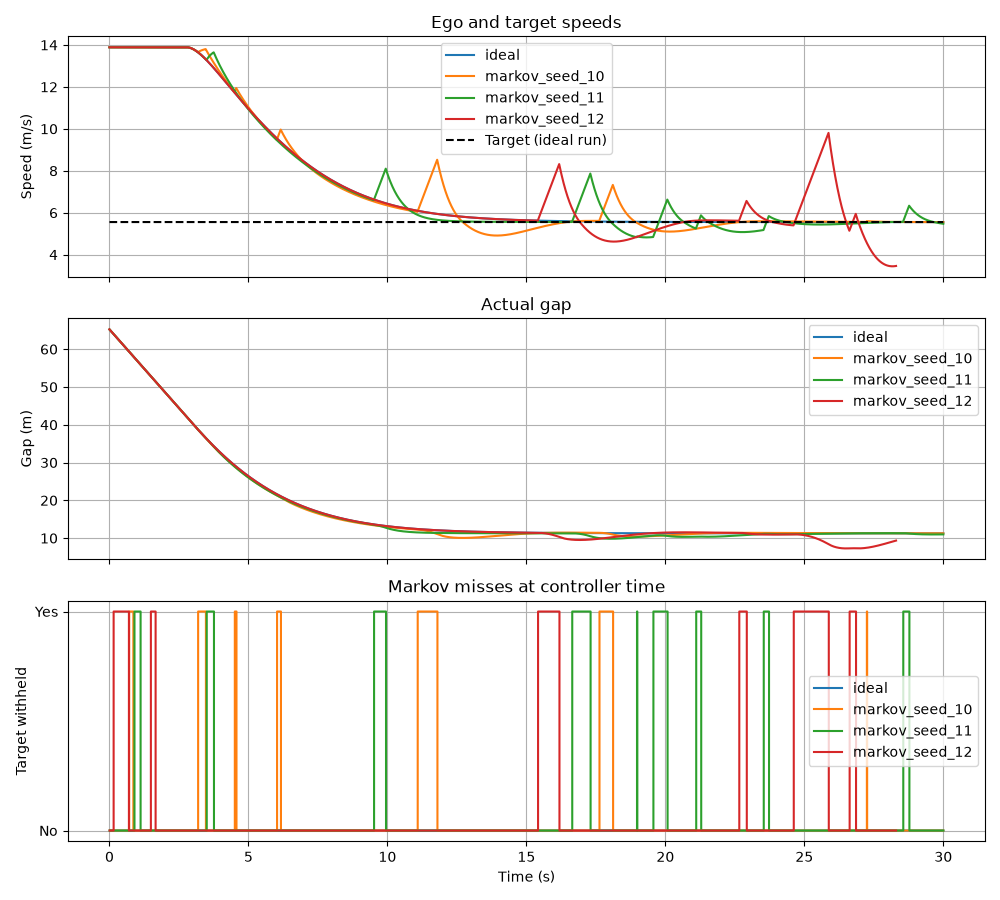

In [341]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

for run in runs:
    label = run["label"]
    ego = [row for row in run["truth"] if row["role"] == "ego"]
    axes[0].plot(
        [float(row["time_s"]) for row in ego],
        [float(row["speed_mps"]) for row in ego],
        label=label,
    )
    axes[1].plot(
        [float(row["time_s"]) for row in run["results"]],
        [float(row["truth_min_gap_m"]) if row["truth_min_gap_m"] else float("nan")
         for row in run["results"]],
        label=label,
    )
    axes[2].step(
        [float(row["controller_time_s"]) for row in run["detections"]],
        [bool(json.loads(row["dropped_target_ids"])) for row in run["detections"]],
        where="post",
        label=label,
    )

target = [row for row in runs[0]["truth"] if row["object_id"] == "1"]
axes[0].plot(
    [float(row["time_s"]) for row in target],
    [float(row["speed_mps"]) for row in target],
    "k--", label="Target (ideal run)",
)
axes[0].set_title("Ego and target speeds")
axes[0].set_ylabel("Speed (m/s)")
axes[1].set_title("Actual gap")
axes[1].set_ylabel("Gap (m)")
axes[2].set_title("Markov misses at controller time")
axes[2].set_ylabel("Target withheld")
axes[2].set_yticks([0, 1], ["No", "Yes"])
axes[2].set_xlabel("Time (s)")

for axis in axes:
    axis.legend()
    axis.grid()

plt.tight_layout()
plt.show()
